# Logistic Regression (Binary Classification) - Optimizer Comparison

This main notebook trains the same degree-2 polynomial logistic regression model with five optimizers written from scratch in NumPy, then compares their loss, accuracy, precision, recall and F1 score.

## Optimizer Notebooks

| # | Notebook |
|---|----------|
| 1 | [Batch Gradient Descent](01_Batch_Gradient_Descent.ipynb) |
| 2 | [Stochastic Gradient Descent](02_Stochastic_Gradient_Descent.ipynb) |
| 3 | [Mini-Batch GD with Momentum](03_MiniBatch_GD_with_Momentum.ipynb) |
| 4 | [RMSprop](04_RMSprop.ipynb) |
| 5 | [Adam](05_Adam.ipynb) |

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

## Dataset

In [2]:
np.random.seed(42)
number_of_samples = 100
X = np.random.uniform(-3, 3, size=(number_of_samples, 2))
distance_squared = X[:, 0] ** 2 + X[:, 1] ** 2
noise = np.random.normal(0, 1, number_of_samples)
y = ((distance_squared + noise) < 5).astype(int).reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class 0:", np.sum(y == 0), " Class 1:", np.sum(y == 1))

X shape: (100, 2)
y shape: (100, 1)
Class 0: 62  Class 1: 38


## Preprocessing

In [3]:
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_poly)
X_scaled[:, 0] = 1

print("Features:", poly.get_feature_names_out(["x1", "x2"]))
print("X_scaled shape:", X_scaled.shape)

Features: ['1' 'x1' 'x2' 'x1^2' 'x1 x2' 'x2^2']
X_scaled shape: (100, 6)


## Sigmoid, Loss and Gradient

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def compute_loss(X, y, weights):
    predictions = sigmoid(X @ weights)
    predictions = np.clip(predictions, 1e-10, 1 - 1e-10)
    return -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))


def compute_gradient(X, y, weights):
    predictions = sigmoid(X @ weights)
    return X.T @ (predictions - y) / len(y)

## Optimizers

In [5]:
def train_batch_gd(learning_rate=0.1, epochs=500):
    weights = np.zeros((X_scaled.shape[1], 1))
    loss_history = []
    for epoch in range(epochs):
        gradient = compute_gradient(X_scaled, y, weights)
        weights = weights - learning_rate * gradient
        loss_history.append(compute_loss(X_scaled, y, weights))
    return weights, loss_history


def train_sgd(learning_rate=0.01, epochs=100):
    weights = np.zeros((X_scaled.shape[1], 1))
    loss_history = []
    for epoch in range(epochs):
        for i in np.random.permutation(number_of_samples):
            gradient = compute_gradient(X_scaled[i:i + 1], y[i:i + 1], weights)
            weights = weights - learning_rate * gradient
        loss_history.append(compute_loss(X_scaled, y, weights))
    return weights, loss_history


def train_momentum(learning_rate=0.05, epochs=200, batch_size=16, beta=0.9):
    weights = np.zeros((X_scaled.shape[1], 1))
    velocity = np.zeros_like(weights)
    loss_history = []
    for epoch in range(epochs):
        shuffled_indices = np.random.permutation(number_of_samples)
        X_shuffled = X_scaled[shuffled_indices]
        y_shuffled = y[shuffled_indices]
        for start in range(0, number_of_samples, batch_size):
            gradient = compute_gradient(X_shuffled[start:start + batch_size], y_shuffled[start:start + batch_size], weights)
            velocity = beta * velocity + learning_rate * gradient
            weights = weights - velocity
        loss_history.append(compute_loss(X_scaled, y, weights))
    return weights, loss_history


def train_rmsprop(learning_rate=0.01, epochs=200, batch_size=16, beta=0.9, epsilon=1e-8):
    weights = np.zeros((X_scaled.shape[1], 1))
    squared_gradient_average = np.zeros_like(weights)
    loss_history = []
    for epoch in range(epochs):
        shuffled_indices = np.random.permutation(number_of_samples)
        X_shuffled = X_scaled[shuffled_indices]
        y_shuffled = y[shuffled_indices]
        for start in range(0, number_of_samples, batch_size):
            gradient = compute_gradient(X_shuffled[start:start + batch_size], y_shuffled[start:start + batch_size], weights)
            squared_gradient_average = beta * squared_gradient_average + (1 - beta) * gradient ** 2
            weights = weights - learning_rate * gradient / (np.sqrt(squared_gradient_average) + epsilon)
        loss_history.append(compute_loss(X_scaled, y, weights))
    return weights, loss_history


def train_adam(learning_rate=0.01, epochs=200, batch_size=16, beta1=0.9, beta2=0.999, epsilon=1e-8):
    weights = np.zeros((X_scaled.shape[1], 1))
    first_moment = np.zeros_like(weights)
    second_moment = np.zeros_like(weights)
    step = 0
    loss_history = []
    for epoch in range(epochs):
        shuffled_indices = np.random.permutation(number_of_samples)
        X_shuffled = X_scaled[shuffled_indices]
        y_shuffled = y[shuffled_indices]
        for start in range(0, number_of_samples, batch_size):
            step += 1
            gradient = compute_gradient(X_shuffled[start:start + batch_size], y_shuffled[start:start + batch_size], weights)
            first_moment = beta1 * first_moment + (1 - beta1) * gradient
            second_moment = beta2 * second_moment + (1 - beta2) * gradient ** 2
            first_moment_corrected = first_moment / (1 - beta1 ** step)
            second_moment_corrected = second_moment / (1 - beta2 ** step)
            weights = weights - learning_rate * first_moment_corrected / (np.sqrt(second_moment_corrected) + epsilon)
        loss_history.append(compute_loss(X_scaled, y, weights))
    return weights, loss_history

## Evaluation Function

In [6]:
def evaluate(weights):
    y_pred = (sigmoid(X_scaled @ weights) >= 0.5).astype(int)
    true_positive = np.sum((y_pred == 1) & (y == 1))
    true_negative = np.sum((y_pred == 0) & (y == 0))
    false_positive = np.sum((y_pred == 1) & (y == 0))
    false_negative = np.sum((y_pred == 0) & (y == 1))
    accuracy = (true_positive + true_negative) / len(y)
    precision = true_positive / (true_positive + false_positive)
    recall = true_positive / (true_positive + false_negative)
    f1 = 2 * precision * recall / (precision + recall)
    loss = compute_loss(X_scaled, y, weights)
    return loss, accuracy, precision, recall, f1

## Training All Optimizers

In [7]:
optimizers = {
    "Batch GD": train_batch_gd,
    "SGD": train_sgd,
    "Mini-Batch + Momentum": train_momentum,
    "RMSprop": train_rmsprop,
    "Adam": train_adam,
}

random_state = np.random.get_state()
results = {}
for name, train_function in optimizers.items():
    np.random.set_state(random_state)
    weights, loss_history = train_function()
    results[name] = {"weights": weights, "loss_history": loss_history, "metrics": evaluate(weights)}

print(f"{'Optimizer':<24}{'Loss':>8}{'Accuracy':>10}{'Precision':>11}{'Recall':>8}{'F1':>8}")
print("-" * 69)
for name, result in results.items():
    loss, accuracy, precision, recall, f1 = result["metrics"]
    print(f"{name:<24}{loss:>8.4f}{accuracy:>10.4f}{precision:>11.4f}{recall:>8.4f}{f1:>8.4f}")

Optimizer                   Loss  Accuracy  Precision  Recall      F1
---------------------------------------------------------------------
Batch GD                  0.1225    0.9800     0.9737  0.9737  0.9737
SGD                       0.0943    0.9800     0.9737  0.9737  0.9737
Mini-Batch + Momentum     0.0563    0.9900     1.0000  0.9737  0.9867
RMSprop                   0.0653    0.9800     0.9737  0.9737  0.9737
Adam                      0.0814    0.9800     0.9737  0.9737  0.9737


## Loss Curves and Metrics Comparison

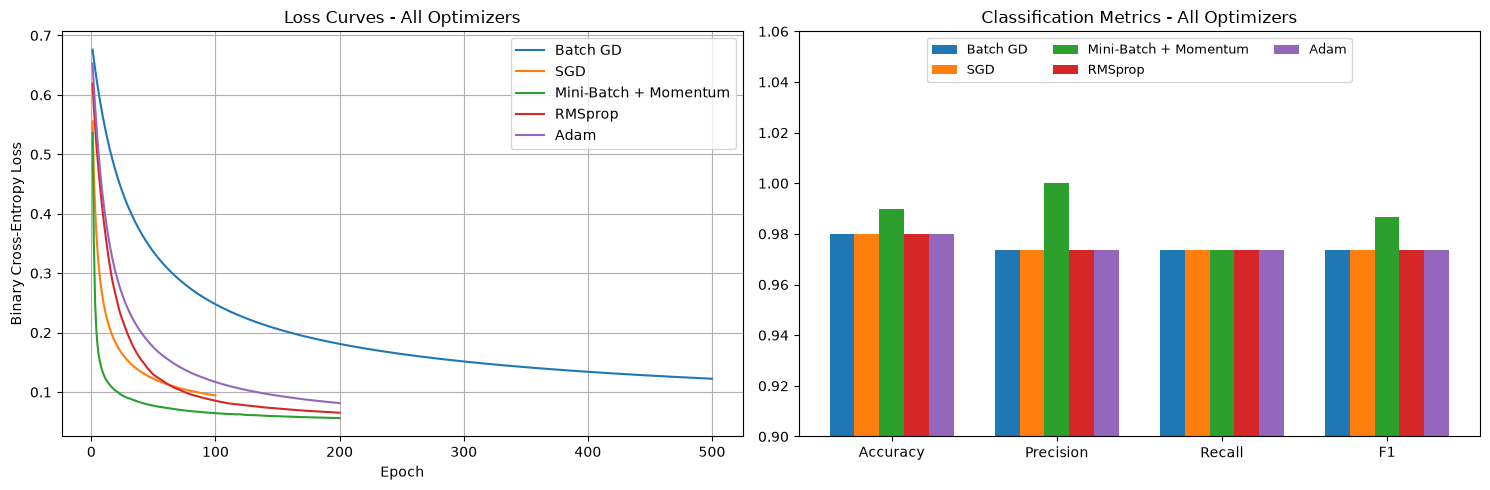

In [8]:
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
bar_width = 0.15
positions = np.arange(len(metric_names))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, result in results.items():
    axes[0].plot(range(1, len(result["loss_history"]) + 1), result["loss_history"], label=name)
axes[0].set_title("Loss Curves - All Optimizers")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True)

for index, (name, result) in enumerate(results.items()):
    axes[1].bar(positions + index * bar_width, result["metrics"][1:], bar_width, label=name)
axes[1].set_xticks(positions + 2 * bar_width)
axes[1].set_xticklabels(metric_names)
axes[1].set_ylim(0.9, 1.06)
axes[1].set_title("Classification Metrics - All Optimizers")
axes[1].legend(loc="upper center", ncol=3, fontsize=9)

plt.tight_layout()
plt.show()

## Decision Boundaries

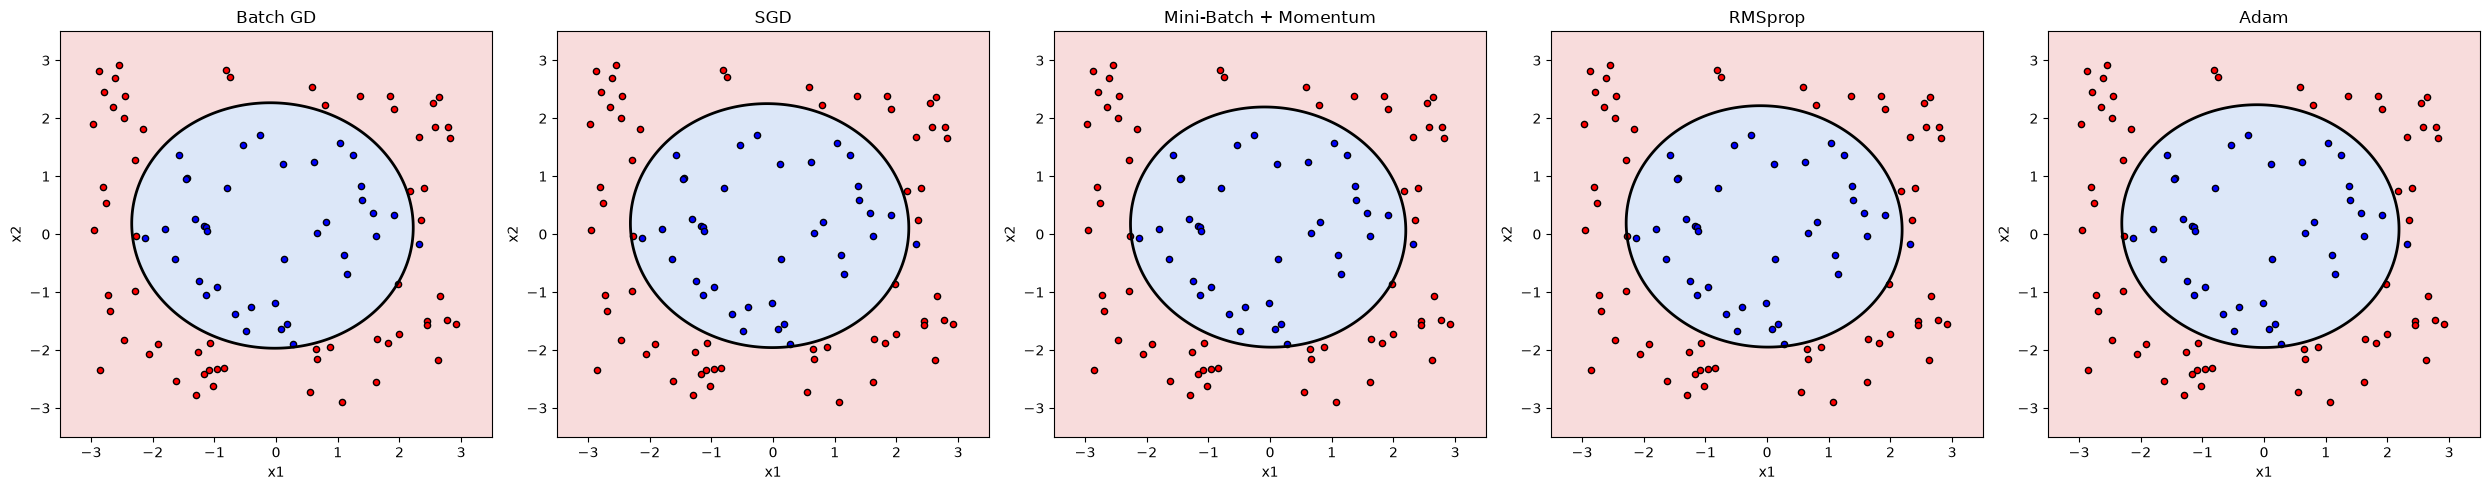

In [9]:
x1_grid, x2_grid = np.meshgrid(np.linspace(-3.5, 3.5, 200), np.linspace(-3.5, 3.5, 200))
grid_scaled = scaler.transform(poly.transform(np.c_[x1_grid.ravel(), x2_grid.ravel()]))
grid_scaled[:, 0] = 1

fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for axis, (name, result) in zip(axes, results.items()):
    grid_probabilities = sigmoid(grid_scaled @ result["weights"]).reshape(x1_grid.shape)
    axis.contourf(x1_grid, x2_grid, grid_probabilities, levels=[0, 0.5, 1], colors=["#f4c6c6", "#c6d8f4"], alpha=0.6)
    axis.contour(x1_grid, x2_grid, grid_probabilities, levels=[0.5], colors="black", linewidths=2)
    axis.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], color="red", edgecolor="black", s=20)
    axis.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], color="blue", edgecolor="black", s=20)
    axis.set_title(name)
    axis.set_xlabel("x1")
    axis.set_ylabel("x2")

plt.tight_layout()
plt.show()

## Conclusion

All five optimizers learn a circular decision boundary and reach about 98-99% accuracy on this dataset. Mini-Batch GD with Momentum reaches the lowest loss. RMSprop and Adam converge quickly because they adapt the step size for each weight. Plain Batch GD is the slowest to converge, even with more epochs.